<center><h1>Blombach_George_HW7</h1></center>

Name: George Blombach | Github Username: gblombach | USC ID: 2416-0961-99

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [60]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC, LinearSVC
from sklearn.base import clone
from sklearn.metrics import hamming_loss, accuracy_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
#7,195 observations, 22 MFCC predictors, with 4 families, 8 genera, and 10 species
csv_data = pd.read_csv('../data/Frogs_MFCCs.csv', na_values='na')
display(csv_data.shape)
#display(csv_data.isna().sum().to_frame("Missing Values")) #check for missing values
labels = ["Family", "Genus", "Species"]

(7195, 26)

In [3]:
X = csv_data.iloc[:,:22].copy()                          # get MFCC Features
y = csv_data[labels].copy()                              # get labels 
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.7, shuffle=True, random_state=333)
X_train = X_train.reset_index(drop=True)                 # Reset indices 
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
display(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(5036, 22)

(2159, 22)

(5036, 3)

(2159, 3)

### (b) Train a classifier for each label

#### (i) Research

Exact match and Hamming loss are two methods that can be used to evaluate multi-label classification:
- **Exact match**, also referred to as subset accuracy, requires the entire predicted set of labels for an observation to match the true set of labels. Consequently, it is a strict measure because an observation is considered incorrectly classified when even one of its labels is predicted incorrectly.
- **Hamming loss** evaluates predictions at the individual-label level and measures the fraction of instance-label pairs that are misclassified. Thus, unlike exact match, Hamming loss distinguishes between predictions in which only one label is incorrect and predictions in which all labels are incorrect.

For exact match, a higher score is better, with 1 representing perfect classification, while for Hamming loss a lower value is better, with 0 representing no incorrectly classified labels.References:

- Tsoumakas, G., Katakis, I., & Vlahavas, I. (2010). “Mining Multi-label Data.” In *Data Mining and Knowledge Discovery Handbook*, 2nd ed., Springer.
- Zhang, M.-L., & Zhou, Z.-H. (2014). “A Review on Multi-Label Learning Algorithms.” *IEEE Transactions on Knowledge and Data Engineering*, 26(8), 1819–1837.


#### (ii) Train a SVM for each of the labels

In [4]:
#Evaluation function
def evaluate_model(y_true, y_pred, model):
    exact_match = (y_true[labels].to_numpy()  == y_pred[labels].to_numpy()).all(axis=1).mean() #Exact match: True only when Family, Genus, AND Species are all correct
    hamming = (y_true[labels].to_numpy() != y_pred[labels].to_numpy()).mean() # Hamming loss: Fraction of individual labels predicted incorrectly
    hamming_score = 1 - hamming # Hamming score defined here as 1 - Hamming loss
    results = {"Model": model, "Exact Match": exact_match, "Hamming Loss": hamming, "Hamming Score": hamming_score}

    for label in labels:  # accuracy_score is fine here because each call contains only ONE multiclass output
        results[f"{label} Accuracy"] = accuracy_score(y_true[label], y_pred[label])
    return results
cv = StratifiedKFold(n_splits=10, shuffle=True,random_state=333)                        #10-fold cross-validation.
C_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0, 100000.0, 1000000.0]   #C controls the penalty for misclassification
sigma_values = np.arange(0.1, 2.1, 0.1)                                                 #sigma .1 to 2.0
gamma_values = 1 / (2 * sigma_values ** 2)                                              #gamma

# Tuning function
def tune_classifier(estimator, parameter_grid, X_train, y_train, X_test, model):
    predictions = pd.DataFrame(index=range(len(X_test)), columns=labels)
    best_parameters = {}; best_cv_scores = {}; fitted_searches = {}
    for label in labels:
        print(f"\nTuning {model} for {label}...")
        grid_search = GridSearchCV(estimator=clone(estimator), param_grid=parameter_grid, scoring="accuracy", cv=cv, n_jobs=-1, refit=True)
        grid_search.fit(X_train, y_train[label])
        predictions[label] = grid_search.predict(X_test)
        best_parameters[label] = grid_search.best_params_
        best_cv_scores[label] = grid_search.best_score_
        fitted_searches[label] = grid_search
        best_params = {key: float(value) if isinstance(value, np.floating) else value for key, value in grid_search.best_params_.items()}
        print("Best parameters:", best_params, "\nBest mean CV accuracy:", round(grid_search.best_score_, 4))
    return (predictions, best_parameters, best_cv_scores, fitted_searches)

gaussian_svm = SVC(kernel="rbf", decision_function_shape="ovr")
gaussian_parameter_grid = {"C": C_values,"gamma": gamma_values}
(gaussian_predictions, gaussian_best_parameters, gaussian_cv_scores, gaussian_searches) = tune_classifier(estimator=gaussian_svm, 
            parameter_grid=gaussian_parameter_grid, X_train=X_train, y_train=y_train, X_test=X_test, model="Gaussian SVM")

gaussian_parameter_rows = []

for label in labels:
    best_C = gaussian_best_parameters[label]["C"]
    best_gamma = gaussian_best_parameters[label]["gamma"]
    best_sigma = np.sqrt(1 / (2 * best_gamma))
    gaussian_parameter_rows.append({"Label": label, "Best C": best_C, "Best Gamma": best_gamma, "Best Sigma": best_sigma,
                                    "Best CV Accuracy": gaussian_cv_scores[label]})
gaussian_parameter_table = pd.DataFrame(gaussian_parameter_rows)
display(gaussian_parameter_table.style.format({"Best C": "{:.6g}", "Best Gamma": "{:.6g}", "Best Sigma": "{:.4f}", "Best CV Accuracy": "{:.4f}" }).hide(axis="index"))
gaussian_results = evaluate_model(y_true=y_test, y_pred=gaussian_predictions, model="Gaussian SVM Binary Relevance")
display(pd.DataFrame([gaussian_results]).style.format({column: "{:.4f}" for column in gaussian_results if column != "Model"}).hide(axis="index"))


Tuning Gaussian SVM for Family...
Best parameters: {'C': 100.0, 'gamma': 2.0} 
Best mean CV accuracy: 0.9934

Tuning Gaussian SVM for Genus...
Best parameters: {'C': 10.0, 'gamma': 3.1249999999999996} 
Best mean CV accuracy: 0.9913

Tuning Gaussian SVM for Species...
Best parameters: {'C': 10.0, 'gamma': 2.0} 
Best mean CV accuracy: 0.9905


Label,Best C,Best Gamma,Best Sigma,Best CV Accuracy
Family,100,2,0.5000,0.9934
Genus,10,3.125,0.4000,0.9913
Species,10,2,0.5000,0.9905


Model,Exact Match,Hamming Loss,Hamming Score,Family Accuracy,Genus Accuracy,Species Accuracy
Gaussian SVM Binary Relevance,0.9880,0.0063,0.9937,0.9944,0.9940,0.9926


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [14]:
l1_pipeline = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty="l1", dual=False, max_iter=100000, random_state=333))])
l1_parameter_grid = {"svm__C": C_values}
(l1_predictions, l1_best_parameters, l1_cv_scores, l1_searches) = tune_classifier(estimator=l1_pipeline, 
                parameter_grid=l1_parameter_grid, X_train=X_train, y_train=y_train, X_test=X_test, model="L1-Penalized SVM")
l1_parameter_table = pd.DataFrame([{"Label": label, "Best C": l1_best_parameters[label]["svm__C"], "Best CV Accuracy": l1_cv_scores[label]}
    for label in labels])
display(l1_parameter_table.style.format({"Best C": "{:.6g}", "Best CV Accuracy": "{:.4f}"}).hide(axis="index"))
# Evaluate the L1-penalized SVM
l1_results = evaluate_model(y_true=y_test, y_pred=l1_predictions, model="L1-Penalized SVM")
display(pd.DataFrame([l1_results]).style.format({column: "{:.4f}" for column in l1_results if column != "Model"}).hide(axis="index"))


Tuning L1-Penalized SVM for Family...
Best parameters: {'svm__C': 100.0} 
Best mean CV accuracy: 0.9355

Tuning L1-Penalized SVM for Genus...
Best parameters: {'svm__C': 100.0} 
Best mean CV accuracy: 0.9515

Tuning L1-Penalized SVM for Species...
Best parameters: {'svm__C': 100.0} 
Best mean CV accuracy: 0.9585


Label,Best C,Best CV Accuracy
Family,100,0.9355
Genus,100,0.9515
Species,100,0.9585


Model,Exact Match,Hamming Loss,Hamming Score,Family Accuracy,Genus Accuracy,Species Accuracy
L1-Penalized SVM,0.9171,0.0511,0.9489,0.9342,0.9509,0.9616


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [22]:
#address class imbalance by applying SMOTE separately for each of the three labels before fitting the L1-penalized SVM
smote_l1_pipeline = ImbPipeline([("scaler", StandardScaler()),("smote", SMOTE(random_state=333,k_neighbors=5)),
    ("svm",LinearSVC(penalty="l1", dual=False, max_iter=100000, random_state=333))])
smote_l1_parameter_grid = {"svm__C": C_values}
(smote_predictions, smote_best_parameters, smote_cv_scores, smote_searches) = tune_classifier(estimator=smote_l1_pipeline,
    parameter_grid=smote_l1_parameter_grid, X_train=X_train, y_train=y_train, X_test=X_test, model="SMOTE + L1-Penalized SVM")
smote_parameter_table = pd.DataFrame([{"Label": label, "Best C": smote_best_parameters[label]["svm__C"],"Best CV Accuracy": smote_cv_scores[label]}
    for label in labels])
display(smote_parameter_table.style.format({"Best C": "{:.6g}", "Best CV Accuracy": "{:.4f}"}).hide(axis="index"))
smote_results = evaluate_model(y_true=y_test, y_pred=smote_predictions, model="SMOTE + L1-SVM Binary Relevance")
display(pd.DataFrame([smote_results]).style.format({column: "{:.4f}" for column in smote_results if column != "Model"}).hide(axis="index"))
# final comparison
required_comparison = pd.DataFrame([gaussian_results, l1_results, smote_results])
required_comparison = required_comparison.sort_values(by=["Exact Match", "Hamming Loss"], ascending=[False, True]).reset_index(drop=True)
display(required_comparison.style.format({column: "{:.4f}"for column in required_comparison.columns if column != "Model"}).hide(axis="index"))


Tuning SMOTE + L1-Penalized SVM for Family...
Best parameters: {'svm__C': 1.0} 
Best mean CV accuracy: 0.915

Tuning SMOTE + L1-Penalized SVM for Genus...
Best parameters: {'svm__C': 1.0} 
Best mean CV accuracy: 0.916

Tuning SMOTE + L1-Penalized SVM for Species...
Best parameters: {'svm__C': 1.0} 
Best mean CV accuracy: 0.9563


,Label,Best C,Best CV Accuracy
0,Family,1,0.9150
1,Genus,1,0.9160
2,Species,1,0.9563


Model,Exact Match,Hamming Loss,Hamming Score,Family Accuracy,Genus Accuracy,Species Accuracy
SMOTE + L1-SVM Binary Relevance,0.8680,0.0709,0.9291,0.9166,0.9157,0.9551


Model,Exact Match,Hamming Loss,Hamming Score,Family Accuracy,Genus Accuracy,Species Accuracy
Gaussian SVM Binary Relevance,0.9880,0.0063,0.9937,0.9944,0.9940,0.9926
L1-Penalized SVM,0.9171,0.0511,0.9489,0.9342,0.9509,0.9616
SMOTE + L1-SVM Binary Relevance,0.8680,0.0709,0.9291,0.9166,0.9157,0.9551


## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [50]:
# Function for selecting best k using Silhouettes for Monte Carlo simulation
def select_best_k(X, seed):
    best_k = None
    best_silhouette = -np.inf
    best_cluster_labels = None
    for k in range(2, 51):                                           #k=1 is excluded because the Silhouette score requires at least two clusters   
        kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
        cluster_labels = kmeans.fit_predict(X)                       #Select k from 2 through 50 using the largest Silhouette score. 
        silhouette = silhouette_score(X, cluster_labels)
        if silhouette > best_silhouette:
            best_k = k
            best_silhouette = silhouette
            best_cluster_labels = cluster_labels.copy()
    return best_k, best_silhouette, best_cluster_labels

best_k, best_silhouette, cluster_labels = select_best_k(X=X,seed=0)            # test it!
print("Selected k:", best_k, "\nSilhouette score:", round(best_silhouette, 6))
print("Unique cluster labels:", np.unique(cluster_labels))
cluster_sizes = pd.Series(cluster_labels).value_counts().sort_index()
print("Cluster Sizes:\n", cluster_sizes.to_string())

Selected k: 4 
Silhouette score: 0.378751
Unique cluster labels: [0 1 2 3]
Cluster Sizes: 0    3568
1    1982
2    1031
3     614


### (b) Determine which family is the majority

In [42]:
# Function to assign majority labels
def assign_labels(y_true, cluster_labels):
    y_true = y_true.reset_index(drop=True)
    cluster_labels = np.asarray(cluster_labels)
    y_pred = pd.DataFrame(index=y_true.index, columns=y_true.columns, dtype=object)
    majority_labels = {}
    for cluster in np.unique(cluster_labels):
        cluster_mask = cluster_labels == cluster
        cluster_majority = {}
        for label in y_true.columns:
            majority = (y_true.loc[cluster_mask, label].mode().iloc[0])
            cluster_majority[label] = majority
            y_pred.loc[cluster_mask, label] = majority
        majority_labels[int(cluster)] = cluster_majority
    return y_pred, majority_labels

y_pred, majority_labels = assign_labels(y_true=y, cluster_labels=cluster_labels)
majority_table = (pd.DataFrame.from_dict(majority_labels, orient="index").rename_axis("Cluster").reset_index())
print(majority_table.to_string(index=False))

 Cluster          Family     Genus                Species
       0         Hylidae Hypsiboas   HypsiboasCinerascens
       1   Dendrobatidae  Ameerega     Ameeregatrivittata
       2 Leptodactylidae Adenomera AdenomeraHylaedactylus
       3         Hylidae Hypsiboas      HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [43]:
# Function to calcuate hamming distance, score, and loss
def calculate_hamming(y_true, y_pred):
    true_labels = y_true.to_numpy()
    predicted_labels = y_pred.to_numpy()
    mismatches = true_labels != predicted_labels                    # True for every incorrectly assigned label
    observation_distances = mismatches.sum(axis=1)                  # Number of incorrect labels for each observation
    hamming_distance = observation_distances.mean()                 # Average number of incorrect labels per observation
    hamming_loss = mismatches.mean()                                # Proportion of all individual labels that are incorrect
    hamming_score = 1 - hamming_loss                                # Proportion of all individual labels that are correct
    return hamming_distance, hamming_loss, hamming_score

hamming_distance, hamming_loss, hamming_score = (calculate_hamming(y_true=y, y_pred=y_pred))
print("Average Hamming distance:", round(hamming_distance, 6),"\nHamming loss:", round(hamming_loss, 6), "\nHamming score:", round(hamming_score, 6))

Average Hamming distance: 0.667269 
Hamming loss: 0.222423 
Hamming score: 0.777577


##### Final Monte Carlo Simulation

In [49]:
# Function to run parts (a), (b), and (c) once
def run_one_simulation(X, y, seed):
    best_k, best_silhouette, cluster_labels = select_best_k(X=X, seed=seed)                       # Part (a): Select k and obtain the winning cluster assignments.
    y_pred, majority_labels = assign_labels(y_true=y, cluster_labels=cluster_labels)              # Part (b): Determine and assign each cluster's majority labels.
    hamming_distance, hamming_loss, hamming_score = (calculate_hamming(y_true=y, y_pred=y_pred))   # Part (c): Calculate the Hamming metrics.
    return {
        "Run": seed + 1, "k": best_k, "Silhouette": best_silhouette,"Hamming Distance": hamming_distance, "Hamming Loss": hamming_loss,
        "Hamming Score": hamming_score, "Majority Labels": majority_labels }

simulation_results = []
for seed in range(50):                                              # run all 50 simulations
    #print(seed)
    result = run_one_simulation(X=X,y=y, seed=seed)
    simulation_results.append(result)
results = pd.DataFrame(simulation_results)                          #display final results      

mean_hamming_distance = results["Hamming Distance"].mean()
std_hamming_distance = results["Hamming Distance"].std(ddof=1)
print("Mean Hamming distance:",round(mean_hamming_distance, 6))
print("Standard deviation of Hamming distance:", round(std_hamming_distance, 6))

summary = (results[["Hamming Distance","Hamming Loss","Hamming Score"]].agg(["mean", "std"]).T.rename(columns={
            "mean": "Mean","std": "Standard Deviation"}))
print(summary.round(6).to_string())

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
Mean Hamming distance: 0.671889
Standard deviation of Hamming distance: 0.016978
                      Mean  Standard Deviation
Hamming Distance  0.671889            0.016978
Hamming Loss      0.223963            0.005659
Hamming Score     0.776037            0.005659


## 3. ISLR 12.6.2 (p. 546)

### dendorogram sketches for (a) & (b) & (d)

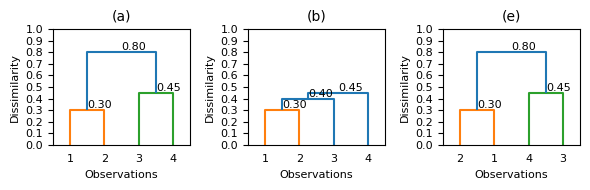

In [119]:
dm = np.array([                      #dissimilarity matrix
    [0,   0.3, 0.4, 0.7],
    [0.3, 0,   0.5, 0.8],
    [0.4, 0.5, 0,   0.45],
    [0.7, 0.8, 0.45, 0]
])
condensed_D = squareform(dm)
fig, axes = plt.subplots(1, 3, figsize=(6, 2))
methods = ['complete', 'single', 'complete']
for i, method in enumerate(methods):
    Z = linkage(condensed_D, method=method)

    if i==0:
        ddata = dendrogram(Z, labels=['1', '2', '3', '4'], ax=axes[i], count_sort="ascending")
    if i==1:
         # Part (b): single linkage with ascending leaves
        Z_plot = Z.copy()
        # Force leaf order 1, 2, 3, 4
        Z_plot[1, [0, 1]] = Z_plot[1, [1, 0]]
        Z_plot[2, [0, 1]] = Z_plot[2, [1, 0]]
        ddata = dendrogram(Z_plot, labels=["1", "2", "3", "4"], ax=axes[i])
    if i==2:
        ddata = dendrogram(Z, labels=['2', '1', '4', '3'], ax=axes[i])
    # Display fusion heights
    for xs, ys in zip(ddata['icoord'], ddata['dcoord']):
        x = (xs[1] + xs[2]) / 2
        y = ys[1]
        axes[i].text(x, y, f'{y:.2f}', ha='left', va='bottom', fontsize=8)
    axes[i].set_xlabel('Observations', fontsize=8)
    axes[i].set_ylabel('Dissimilarity', fontsize=8)
    axes[i].set_yticks(np.arange(0, 1.1, 0.1))
    axes[i].tick_params(axis='both', labelsize=8)
    axes[i].set_ylim(0, 1.0)
axes[0].set_title('(a)', fontsize=10)
axes[1].set_title('(b)', fontsize=10)
axes[2].set_title('(e)', fontsize=10)
plt.tight_layout()
plt.show()

### (c)

From part (a), just before the final fusion at $0.8$, the clusters are $\{1,2\}$ and $\{3,4\}$

### (d)

From part (b), just before the final fusion at $0.45$, the clusters are $\{1,2,3\}$ and $\{4\}$